<center><h1>Blombach_George_HW8</h1></center>

Name: George Blombach | Github Username: gblombach | USC ID: 2416-0961-99

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, \
    f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, pairwise_distances
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans, SpectralClustering

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
#569 instance, 32 total attributes; diagnosis: 357 Benign, 212 Malignant
raw_data = pd.read_csv("../data/wdbc.data", header = None)
#display(raw_data.shape)
mapping = {'M':1, 'B':0}                      #define Malignant/Benign to 1/0 mapping
data = raw_data.copy()
data.columns = ["ID","Diagnosis"] + [f'attr{i}' for i in range(1,31)]
data['Diagnosis'] = data['Diagnosis'].map(mapping) # replace M/B with 1/0 
#print(raw_data.head())
#print(data.head())

### (b) Monte-Carlo Simulation

In [3]:
#print(data.columns.tolist())

In [4]:
# setup data
y = data['Diagnosis'].copy()
X = data.drop(columns=['ID','Diagnosis']).copy()
M = 30 #number of monte carlo simulations
C_grid = np.logspace(-4, 4, 9) #Candidate penalty parameters for  L1-penalized SVM
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
results = []
representative_simulation = {}
# Function for deriving metrics
def calc_metrics(y_true, y_pred, scores):
    return {"Accuracy": accuracy_score(y_true, y_pred), 
            "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
            "AUC": roc_auc_score(y_true, scores)}
# Function for recording results
def log_results(results, run, method, split, y_true, y_pred, scores):
    results.append({"run": run + 1,"method": method, "split": split, 
                    **calc_metrics( y_true, y_pred, scores)})
# Function for ROC and Confusion Matrix
def show_roc_and_cm(y_train, y_test, train_pred, test_pred, train_scores, test_scores, method):
    print("Representative Run for", method,":")
    fig, axes = plt.subplots(nrows=1,ncols=4,figsize=(20, 4))
    ConfusionMatrixDisplay.from_predictions(y_train, train_pred, labels=[0, 1], display_labels=["Benign", "Malignant"], cmap="Blues", colorbar=False, ax=axes[0])
    ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=[0, 1], display_labels=["Benign", "Malignant"], cmap="Blues", colorbar=False, ax=axes[1])
    for ax in axes:
        ax.xaxis.label.set_size(12)
        ax.yaxis.label.set_size(12)
    axes[0].set_title(f"{method}: Training", fontsize=14)
    axes[1].set_title(f"{method}: Testing", fontsize=14)
    fpr, tpr, _ = roc_curve(y_train, train_scores)                   #ROC 
    train_auc = roc_auc_score(y_train, train_scores)
    axes[2].plot(fpr, tpr, linewidth=2, label=f"AUC = {train_auc:.3f}")
    axes[2].plot([0, 1], [0, 1],linestyle=":", color="gray", alpha=0.6)
    axes[2].set_title(f"{method}: Training ROC", fontsize=14)
    axes[2].legend(fontsize=12, loc='lower right')
    fpr, tpr, _ = roc_curve(y_test, test_scores)
    test_auc = roc_auc_score(y_test, test_scores)
    axes[3].plot(fpr, tpr, linewidth=2, label=f"AUC = {test_auc:.3f}")
    axes[3].plot([0, 1], [0, 1], linestyle=":", color="gray", alpha=0.6)
    axes[3].set_title(f"{method}: Testing ROC", fontsize=14)
    axes[3].legend(fontsize=12, loc='lower right')
    for ax in axes[2:4]:
        ax.set_xlabel("False Positive Rate", fontsize=12)
        ax.set_ylabel("True Positive Rate", fontsize=12)
    for ax in axes:
        ax.tick_params(axis="both", labelsize=8)
    plt.tight_layout()
    plt.show()

#### (i) Supervised Learning

Representative Run for Supervised SVM :


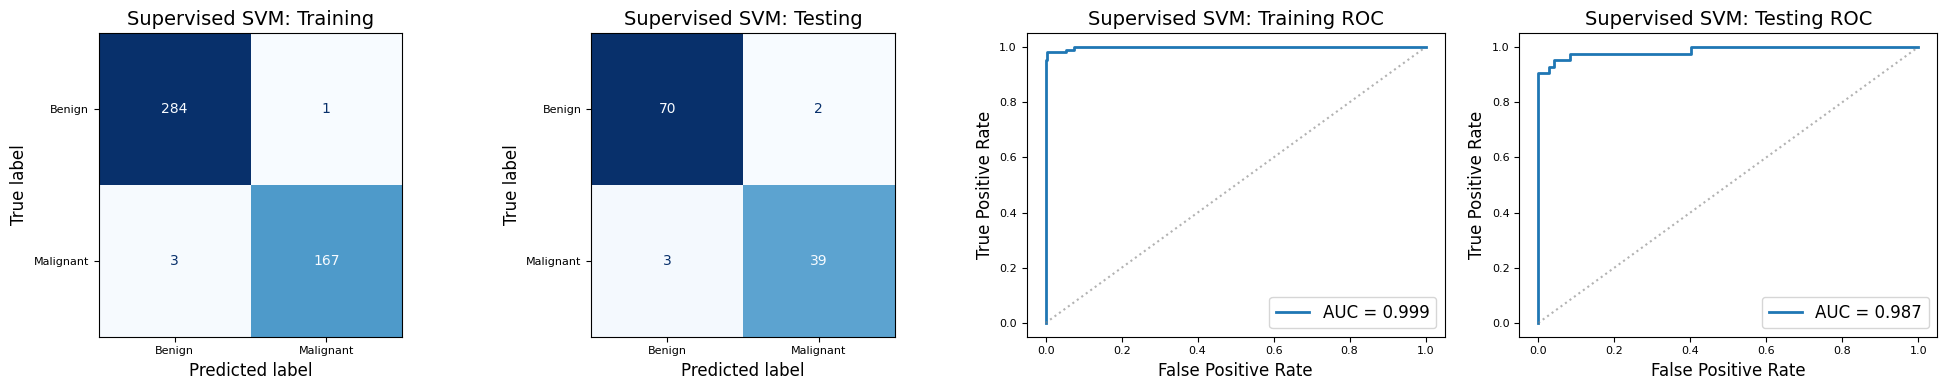

In [5]:
# Function for 5 fold cross validation  
def fit_l1_svm(X_train, y_train, random_state):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    pipeline = Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(penalty="l1", dual=False,
            max_iter=10000, tol=1e-3, random_state=random_state))])
    grid_search = GridSearchCV(estimator=pipeline, param_grid={"svm__C": C_grid},  scoring="accuracy", cv=cv, n_jobs=-1)
    grid_search.fit(X_train, y_train)
    return (grid_search.best_estimator_)
# split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=333)
# function to evaluate model
def evaluate_supervised(X_train, X_test, y_train, y_test, random_state):
    supervised_model = fit_l1_svm(X_train, y_train, random_state=random_state) # fit model
    supervised_train_pred = supervised_model.predict(X_train)                  # training predictions
    supervised_test_pred = supervised_model.predict(X_test)                    # test predictions
    supervised_train_scores = (supervised_model.decision_function(X_train))    # training scores
    supervised_test_scores = (supervised_model.decision_function(X_test))      # test scores 
    supervised_train_metrics = calc_metrics(y_train, supervised_train_pred, supervised_train_scores) # training metrics
    supervised_test_metrics = calc_metrics(y_test, supervised_test_pred, supervised_test_scores)     # test metrics
    return (supervised_train_metrics, supervised_test_metrics, supervised_train_pred, supervised_test_pred, 
            supervised_train_scores, supervised_test_scores)
# perform representive run
(supervised_train_metrics, supervised_test_metrics, supervised_train_pred, supervised_test_pred, supervised_train_scores,
    supervised_test_scores) = evaluate_supervised(X_train, X_test, y_train, y_test, random_state=333)
# show ROC and confusion matrix for representative run
show_roc_and_cm(y_train, y_test, supervised_train_pred, supervised_test_pred, supervised_train_scores,supervised_test_scores , "Supervised SVM")   

#### (ii) Semi-Supervised Learning/ Self-training

In [6]:
#semi_train_results = []
#semi_test_results = []
#semi_best_C = []

##### (A)

In [7]:
def fit_self_l1_svm(X_labeled, y_labeled, X_unlabeled,  random_state):
    initial_model = fit_l1_svm(X_labeled, y_labeled,  random_state)  # Choose C using 5-fold CV on the initial labeled set
    best_C = initial_model.named_steps["svm"].C
    # Final self-training pipeline using the selected C
    model = Pipeline([("scaler", StandardScaler()),("svm", LinearSVC(penalty="l1", dual=False, C=best_C, max_iter=10000,
                tol=1e-3, random_state=random_state))])
    X_labeled = X_labeled.copy().reset_index(drop=True)
    y_labeled = y_labeled.copy().reset_index(drop=True)
    X_unlabeled = X_unlabeled.copy().reset_index(drop=True)
    while len(X_unlabeled) > 0:
        model.fit(X_labeled, y_labeled)                           # Retrain using the current labeled set
        unlabeled_scores = model.decision_function(X_unlabeled)   # Find the distance of every unlabeled observation
                                                                  # from the SVM decision boundary
        farthest_idx = np.argmax(np.abs(unlabeled_scores))        # The largest absolute score is farthest from
        selected_point = X_unlabeled.iloc[[farthest_idx]]         # the decision boundary
        pseudo_label = model.predict(selected_point)[0]           # Use the SVM's prediction, not the true label
        X_labeled = pd.concat([X_labeled, selected_point],ignore_index=True)   # Add the selected point and pseudo-label
        y_labeled = pd.concat([y_labeled, pd.Series([pseudo_label], name=y_labeled.name)],ignore_index=True)
        X_unlabeled = (X_unlabeled.drop(X_unlabeled.index[farthest_idx]).reset_index(drop=True)) # remove the point
    model.fit(X_labeled, y_labeled)                               # Final fit after all unlabeled observations are added
    return model

#function to split data
def split_labeled_unlabeled(X_train, y_train, random_state):
    rng = np.random.default_rng(random_state)
    X_train = X_train.copy().reset_index(drop=True)                      # Reset indices to align positions
    y_train = y_train.copy().reset_index(drop=True)
    positive_idx = np.where(y_train.to_numpy() == 1)[0]
    negative_idx = np.where(y_train.to_numpy() == 0)[0]           # Randomly select 50% of each class as labeled
    labeled_positive_idx = rng.choice(positive_idx,size=len(positive_idx) // 2, replace=False)
    labeled_negative_idx = rng.choice(negative_idx,size=len(negative_idx) // 2, replace=False)
    labeled_idx = np.concatenate([labeled_positive_idx, labeled_negative_idx])
    rng.shuffle(labeled_idx)
    unlabeled_idx = np.setdiff1d(np.arange(len(X_train)), labeled_idx)
    X_labeled = (X_train.iloc[labeled_idx].reset_index(drop=True))
    y_labeled = (y_train.iloc[labeled_idx].reset_index(drop=True))
    X_unlabeled = (X_train.iloc[unlabeled_idx].reset_index(drop=True))

    return X_labeled, y_labeled, X_unlabeled

##### (B)

Representative Run for Semi-Supervised SVM :


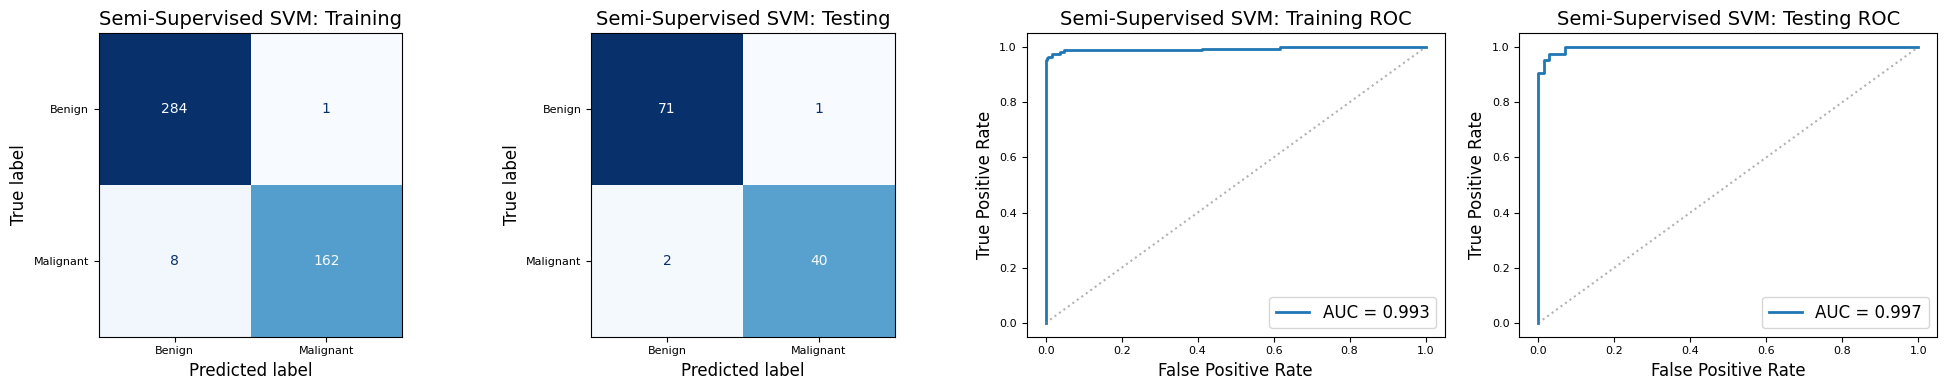

In [17]:
#Perform representative run
def evaluate_semi_supervised(X_train, X_test, y_train, y_test, random_state):
    # Select 50% of each training class as labeled
    X_labeled, y_labeled, X_unlabeled = (split_labeled_unlabeled(X_train, y_train, random_state=random_state))
    semi_supervised_model = fit_self_l1_svm(X_labeled,y_labeled, X_unlabeled, random_state=random_state)
    semi_train_pred = semi_supervised_model.predict(X_train)                          #training prediction
    semi_train_scores = (semi_supervised_model.decision_function(X_train))            #training scores
    semi_test_pred = semi_supervised_model.predict(X_test)                            #testing predictions 
    semi_test_scores = (semi_supervised_model.decision_function(X_test))              #testing decision scores
    semi_train_metrics = calc_metrics(y_train, semi_train_pred, semi_train_scores)    #training metrics
    semi_test_metrics = calc_metrics(y_test, semi_test_pred, semi_test_scores)        #test metrics
    return(semi_train_metrics, semi_test_metrics, semi_train_pred, semi_test_pred, semi_train_scores, semi_test_scores)
#Perform representative run
(semi_train_metrics, semi_test_metrics, semi_train_pred, semi_test_pred, semi_train_scores, semi_test_scores) \
    = evaluate_semi_supervised(X_train, X_test, y_train, y_test, random_state=333)
# show results
show_roc_and_cm(y_train, y_test, semi_train_pred,semi_test_pred, semi_train_scores,semi_test_scores,"Semi-Supervised SVM")

#### (iii) Unsupervised Learning

##### (A)

In [9]:
# Function to fit K-means
def fit_kmeans(X_train, random_state):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    kmeans = KMeans(n_clusters=2, init="random", n_init=50, random_state=random_state) #run 50 times
    kmeans.fit(X_train_scaled)
    return scaler, kmeans

K-means was run 50 times using different random initializations. The solution with the lowest within-cluster sum of squared distances (inertia) was retained, reducing the likelihood of selecting a poor local minimum.

##### (B)

Representative Run for Unsupervised K-Means :


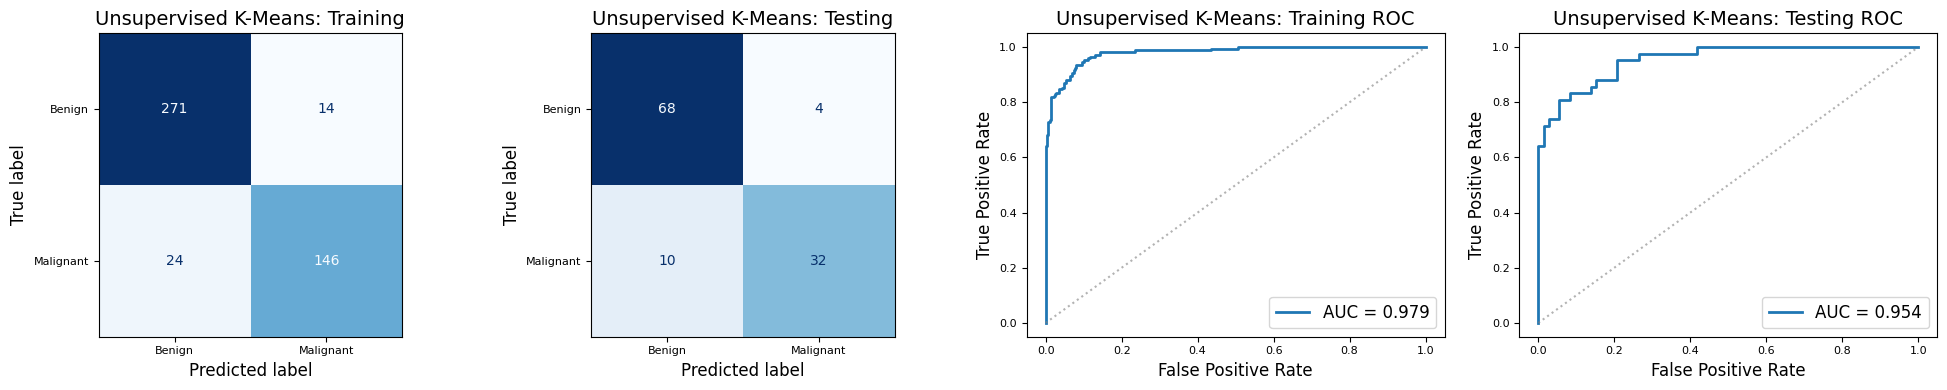

In [10]:
# Function to assign a class to each cluster
def assign_cluster_labels(kmeans, X_train_scaled, y_train):
    cluster_labels = {}
    for cluster in range(2):
        cluster_idx = np.where(kmeans.labels_ == cluster)[0]       #Observations belonging to this cluster
        # Distance from observations to this cluster's center
        distances = np.linalg.norm(X_train_scaled[cluster_idx] - kmeans.cluster_centers_[cluster],axis=1)
        closest_idx = cluster_idx[np.argsort(distances)[:30]]      #Find the 30 closest observations
        majority_label = y_train.iloc[closest_idx].mode().iloc[0]  #Find the majority class
        cluster_labels[cluster] = majority_label
    return cluster_labels
# Function for training predictions
def predict_kmeans_train(kmeans, cluster_labels):
    cluster_pred = kmeans.labels_
    y_pred = np.array([cluster_labels[cluster] for cluster in cluster_pred])
    return y_pred
# Function for test predictions
def predict_kmeans_test(kmeans, X_test_scaled, cluster_labels):
    cluster_pred = kmeans.predict(X_test_scaled)
    y_pred = np.array([cluster_labels[cluster] for cluster in cluster_pred])
    return y_pred    
# Function to calculate K-means scores
def get_kmeans_scores(kmeans, X_scaled, cluster_labels):
    distances = kmeans.transform(X_scaled)
    malignant_cluster = [cluster for cluster, label in cluster_labels.items() if label == 1][0]
    benign_cluster = [cluster for cluster, label in cluster_labels.items() if label == 0][0]
    scores = (distances[:, benign_cluster] - distances[:, malignant_cluster])
    return scores
#define function for evaluating unsupervised
def evaluate_unsupervised(X_train, X_test, y_train, y_test, random_state):
    scaler, kmeans = fit_kmeans(X_train, random_state)
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    cluster_labels = assign_cluster_labels(kmeans, X_train_scaled, y_train)        # assign a class closest to center
    unsup_train_pred = predict_kmeans_train(kmeans, cluster_labels)                 # training predictions
    unsup_train_scores = get_kmeans_scores(kmeans, X_train_scaled, cluster_labels)  # training scores
    unsup_test_pred = predict_kmeans_test(kmeans, X_test_scaled, cluster_labels)    # test predictions
    unsup_test_scores = get_kmeans_scores(kmeans, X_test_scaled, cluster_labels)    # test scores
    unsup_train_metrics = calc_metrics(y_train, unsup_train_pred, unsup_train_scores)
    unsup_test_metrics = calc_metrics(y_test, unsup_test_pred, unsup_test_scores)
    return(unsup_train_metrics, unsup_test_metrics, unsup_train_pred, unsup_test_pred, unsup_train_scores, unsup_test_scores)
# Perform representative run
(unsup_train_metrics, unsup_test_metrics, unsup_train_pred, unsup_test_pred, unsup_train_scores, unsup_test_scores) \
= evaluate_unsupervised(X_train, X_test, y_train, y_test, random_state=333)
# Show ROC curves and confusion matrices for the representative run
show_roc_and_cm(y_train,y_test,unsup_train_pred,unsup_test_pred,unsup_train_scores,unsup_test_scores,"Unsupervised K-Means")

#### (iv) Spectral Clustering

Representative Run for Spectral Clustering :


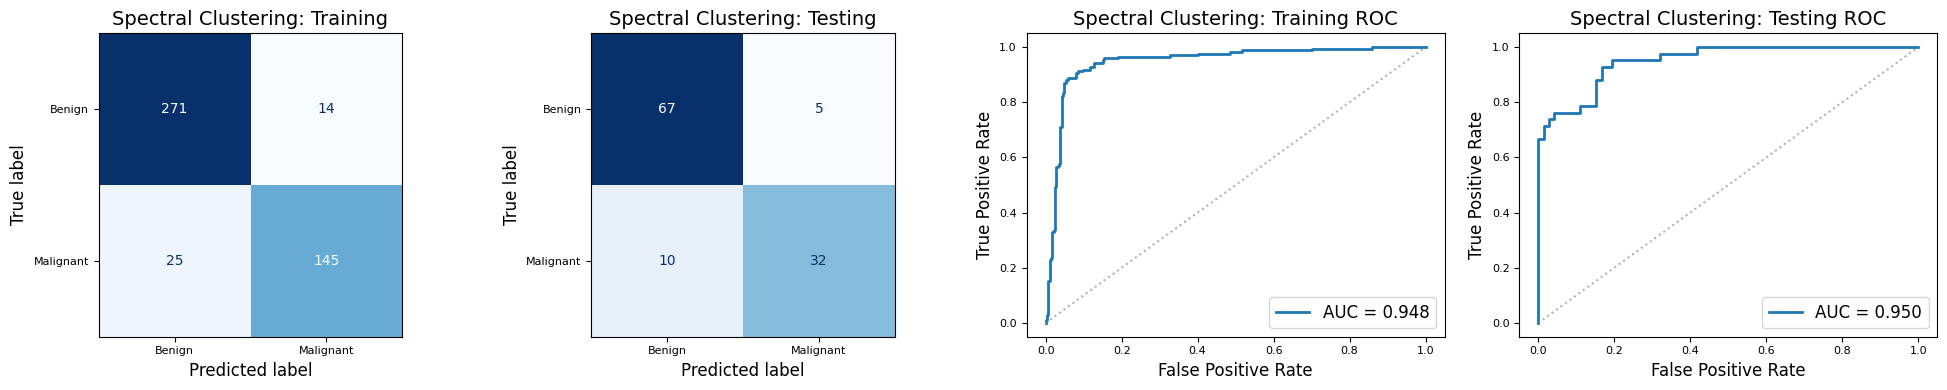

In [11]:
# Function to find gamma with cluster sizes closest to the original class balance
def find_spectral_gamma(X_train_scaled, y_train, random_state):
    target_sizes = np.sort(y_train.value_counts().to_numpy())
    gamma_grid = np.logspace(-5, 0, 100)
    best_gamma = None
    best_difference = np.inf
    for gamma in gamma_grid:
        spectral = SpectralClustering(n_clusters=2, affinity="rbf", gamma=gamma, assign_labels="kmeans", n_init=50,random_state=random_state)
        cluster_pred = spectral.fit_predict(X_train_scaled)
        cluster_sizes = np.sort(np.bincount(cluster_pred, minlength=2))
        difference = np.sum(np.abs(cluster_sizes - target_sizes))    # dif between cluster sizes and true class size
        if difference < best_difference:
            best_difference = difference
            best_gamma = gamma
    return best_gamma
# Function to fit spectral clustering
def fit_spectral(X_train, y_train, random_state):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)        #scale
    best_gamma = find_spectral_gamma(X_train_scaled, y_train, random_state)
    spectral = SpectralClustering(n_clusters=2, affinity="rbf", gamma=best_gamma, assign_labels="kmeans", n_init=50, random_state=random_state)
    cluster_pred = spectral.fit_predict(X_train_scaled)
    return scaler, spectral, cluster_pred, best_gamma
# Function to assign different class labels to the two spectral clusters
def assign_spectral_labels(cluster_pred, y_train):
    y_true = y_train.to_numpy()
    mapping_1 = {0: 0, 1: 1}  # Possible binary mappings: # cluster 0 -> class 0 and cluster 1 -> class 1
    pred_1 = np.array([mapping_1[cluster] for cluster in cluster_pred])
    mapping_2 = {0: 1, 1: 0}  # cluster 0 -> class 1 and cluster 1 -> class 0
    pred_2 = np.array([mapping_2[cluster] for cluster in cluster_pred])
    accuracy_1 = accuracy_score(y_true, pred_1)
    accuracy_2 = accuracy_score(y_true, pred_2)
    if accuracy_1 >= accuracy_2:
        return mapping_1
    return mapping_2
# Function for spectral training predictions
def predict_spectral_train(cluster_pred, cluster_labels):
    y_pred = np.array([cluster_labels[cluster] for cluster in cluster_pred])
    return y_pred
# Function for spectral test predictions
def predict_spectral_test(X_train_scaled, X_test_scaled, cluster_pred, cluster_labels):
    distances = pairwise_distances(X_test_scaled, X_train_scaled)
    nearest_idx = np.argmin(distances, axis=1)
    nearest_clusters = cluster_pred[nearest_idx]
    y_pred = np.array([cluster_labels[cluster] for cluster in nearest_clusters])
    return y_pred
# Function to calculate spectral clustering scores for ROC/AUC
def get_spectral_scores(X_train_scaled, X_eval_scaled, cluster_pred, cluster_labels):
    benign_cluster = [cluster for cluster, label in cluster_labels.items() if label == 0][0]
    malignant_cluster = [cluster for cluster, label in cluster_labels.items() if label == 1][0]
    benign_points = X_train_scaled[cluster_pred == benign_cluster]     # Training observations for ea. spectral cluster
    malignant_points = X_train_scaled[cluster_pred == malignant_cluster]
    benign_distances = pairwise_distances(X_eval_scaled, benign_points) # Distance from observation to observation
    malignant_distances = pairwise_distances(X_eval_scaled, malignant_points)
    d_benign = benign_distances.min(axis=1)         # Distance to closest observation in each cluster
    d_malignant = malignant_distances.min(axis=1)
    scores = d_benign - d_malignant                 # Positive score means relatively closer to malignant cluster
    return scores
# evaluate spectral clustering 
def evaluate_spectral(X_train, X_test, y_train, y_test, random_state):
    scaler, spectral, spectral_clusters, best_gamma = fit_spectral(X_train, y_train, random_state=random_state) # fit spectral clustering
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    spectral_cluster_labels = assign_spectral_labels(spectral_clusters,y_train) # Assign each spectral cluster a class
    spectral_train_pred = predict_spectral_train(spectral_clusters, spectral_cluster_labels) # Training predictions
    spectral_test_pred = predict_spectral_test(X_train_scaled, X_test_scaled, spectral_clusters, spectral_cluster_labels) # Test predictions
    spectral_train_scores = get_spectral_scores(X_train_scaled, X_train_scaled, spectral_clusters, spectral_cluster_labels)
    spectral_test_scores = get_spectral_scores(X_train_scaled, X_test_scaled, spectral_clusters, spectral_cluster_labels)
    spectral_train_metrics = calc_metrics(y_train, spectral_train_pred, spectral_train_scores)
    spectral_test_metrics = calc_metrics(y_test, spectral_test_pred, spectral_test_scores)
    return(spectral_train_metrics, spectral_test_metrics, spectral_train_pred, spectral_test_pred, spectral_train_scores, spectral_test_scores)
# perform representative run
(spectral_train_metrics, spectral_test_metrics, spectral_train_pred, spectral_test_pred, spectral_train_scores, spectral_test_scores) \
= evaluate_spectral(X_train, X_test,y_train, y_test, random_state=333)
# Show ROC curves and confusion matrices for representative run
show_roc_and_cm(y_train,y_test, spectral_train_pred, spectral_test_pred, spectral_train_scores, spectral_test_scores, "Spectral Clustering")

In [12]:
#print("Cluster labels:", spectral_cluster_labels)
#print("Cluster sizes:")
#print(pd.Series(spectral_clusters).value_counts().sort_index())
#print("\nTrue labels within each cluster:")
#print(pd.crosstab(pd.Series(spectral_clusters, name="Cluster"), y_train.rename("True Label")))
#print("Best Gamma:", best_gamma)

#### (v) Compare

In [19]:
# helper function for gathering metrics
def add_results(results, run, method, train_metrics, test_metrics):
    results.append({"Run": run + 1,"Method": method,"Dataset": "Training", **train_metrics})
    results.append({"Run": run + 1,"Method": method,"Dataset": "Testing", **test_metrics})
# Monte Carlo simulation for all four methods
M = 2
for run in range(M):
    random_state = run
    # Use the same stratified 80/20 split for all models in this run
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=random_state)
    (supervised_train_metrics, supervised_test_metrics, supervised_train_pred, supervised_test_pred, supervised_train_scores, supervised_test_scores) \
    = evaluate_supervised(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Supervised L1-SVM", supervised_train_metrics, supervised_test_metrics)
    (semi_train_metrics, semi_test_metrics, semi_train_pred, semi_test_pred, semi_train_scores, semi_test_scores) \
    = evaluate_semi_supervised(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Semi-Supervised L1-SVM", semi_train_metrics, semi_test_metrics)
    (unsup_train_metrics, unsup_test_metrics, unsup_train_pred, unsup_test_pred, unsup_train_scores, unsup_test_scores) \
    = evaluate_unsupervised(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Unsupervised K-Means", unsup_train_metrics, unsup_test_metrics)
    (spectral_train_metrics, spectral_test_metrics, spectral_train_pred, spectral_test_pred, spectral_train_scores, spectral_test_scores) \
    = evaluate_spectral(X_train, X_test, y_train, y_test, random_state=random_state)
    add_results(results, run,"Spectral Clustering", spectral_train_metrics, spectral_test_metrics)
    print(f"Completed run {run + 1} of {M}")

Completed run 1 of 2
Completed run 2 of 2


In [21]:
results_df = pd.DataFrame(results)
summary = (results_df.groupby(["Method", "Dataset"])[metrics].agg(["mean", "std"]))
comparison_table = pd.DataFrame()
for metric in metrics:
    for dataset in ["Training", "Testing"]:
        comparison_table[f"{dataset} {metric}"] = (summary.loc[(slice(None), dataset), (metric, "mean")]
            .droplevel("Dataset").map("{:.4f}".format) + " ± " + summary.loc[(slice(None), dataset), (metric, "std")]
            .droplevel("Dataset").map("{:.4f}".format))
print("Mean ± Standard Deviation Comparison Over", M, "Monte Carlo Runs:")
display(comparison_table)

Mean ± Standard Deviation Comparison Over 2 Monte Carlo Runs:


,Training Accuracy,Testing Accuracy,Training Precision,Testing Precision,Training Recall,Testing Recall,Training F1,Testing F1,Training AUC,Testing AUC
Method,,,,,,,,,,
Semi-Supervised L1-SVM,0.9817 ± 0.0062,0.9605 ± 0.0133,0.9889 ± 0.0025,0.9447 ± 0.0192,0.9618 ± 0.0148,0.9484 ± 0.0179,0.9751 ± 0.0085,0.9465 ± 0.0180,0.9941 ± 0.0033,0.9956 ± 0.0017
Spectral Clustering,0.9066 ± 0.0036,0.9211 ± 0.0096,0.9266 ± 0.0133,0.9125 ± 0.0137,0.8147 ± 0.0032,0.8690 ± 0.0130,0.8670 ± 0.0040,0.8902 ± 0.0134,0.9523 ± 0.0069,0.9704 ± 0.0078
Supervised L1-SVM,0.9890 ± 0.0024,0.9693 ± 0.0144,0.9911 ± 0.0033,0.9532 ± 0.0252,0.9794 ± 0.0032,0.9643 ± 0.0130,0.9852 ± 0.0032,0.9587 ± 0.0192,0.9979 ± 0.0007,0.9950 ± 0.0025
Unsupervised K-Means,0.9066 ± 0.0036,0.8991 ± 0.0240,0.9297 ± 0.0166,0.8896 ± 0.0617,0.8118 ± 0.0064,0.8333 ± 0.0000,0.8666 ± 0.0036,0.8597 ± 0.0289,0.9747 ± 0.0023,0.9674 ± 0.0089


## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

#### (ii) Active

### (c) Average the 50 test errors